# 04 · Numeriikka ja kuvat

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/markomanninen/tgd-geometry-lab/blob/main/notebooks/04_numeriikka_ja_kuvat.ipynb)

Vaihe VIII, välitavoite **M8**. Maxima laskee lausekkeet, ja `lab.numeric` muuntaa ne NumPy-funktioiksi.
Kirja tarkistaa numeeriset arvot analyyttisiä arvoja vasten ennen kuin piirtää ne.

In [1]:
# Asennus: Maxima, tämä repositorio ja Dimiter Prodanovin clifford-paketti.
# Colabissa ajo kestää noin minuutin; paikallisesti asetetaan TGD_ROOT / CLIFFORD_PATH.
import os, sys, shutil
ROOT = os.environ.get("TGD_ROOT", "/content/tgd-geometry-lab")
CLI  = os.environ.get("CLIFFORD_PATH", "/content/clifford")
if not shutil.which("maxima"):
    !apt-get -qq update > /dev/null && apt-get -qq install -y maxima > /dev/null
if not os.path.exists(ROOT):
    !git clone -q --depth 1 https://github.com/markomanninen/tgd-geometry-lab.git {ROOT}
if not os.path.exists(CLI):
    !git clone -q --depth 1 https://github.com/dprodanov/clifford.git {CLI}
sys.path.insert(0, ROOT + "/notebooks")
from tgdlab import Lab
lab = Lab(ROOT, CLI)
!maxima --version 2>/dev/null | tail -1

Maxima 5.50.0


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 130, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False,
    "legend.labelcolor": MUTED})

## Yhtälön tyyppi kosmisen säikeen poikki

Karakteristinen analyysi antaa $s^2=(c_V-2c_K)/(c_V+2c_K)$. Lasketaan arvo suoraan Lagrangen funktion toisista derivaatoista
ja verrataan sitä kaavaan. Kuvassa on käytetty suhdetta $c_V/c_K$, ja $c_K>0$. Kertoimien todelliset arvot ovat avoin kysymys (#27).

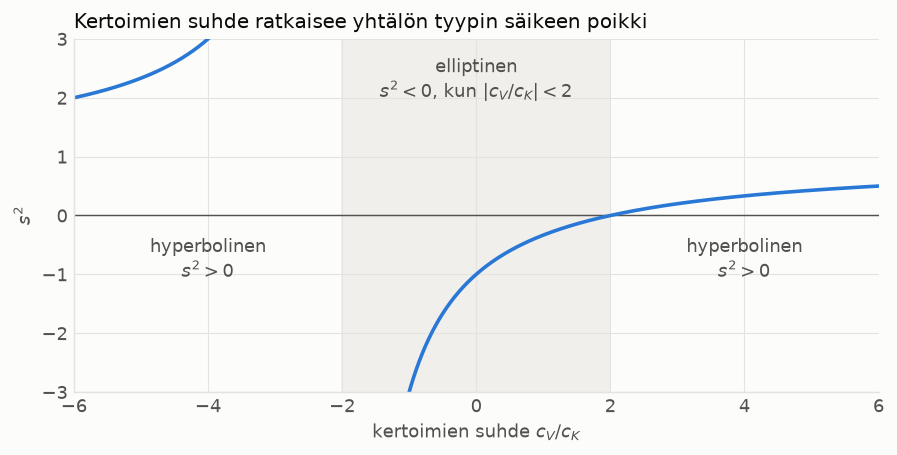

In [3]:
setup = ("GH:H_metric()$ JH:H_kahler()$ eC:[tt,0,0,zz,aa,bb,0,0]$ xC:[tt,zz,aa,bb]$ "
         "pC:[tt=0,zz=0,aa=0,bb=0]$ F:[2,3,7,8]$ "
         "Pa:principal_blocks(GH,JH,H_X,eC,xC,pC,F,[1,3],1,rr,-1)$")
s2 = lab.numeric(setup, "-Pa[2][2][1,1]/Pa[1][1][1,1]", ["rr"])
r = np.linspace(-6, 6, 1201)
r = r[np.abs(r + 2) > 0.02]
exact = (r - 2)/(r + 2)
assert np.max(np.abs(np.asarray(s2(r), float) - exact)) < 1e-9

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.axvspan(-2, 2, color="#f0efec", zorder=0)
ax.axhline(0, color=MUTED, lw=0.8)
ax.plot(r[r < -2], exact[r < -2], color=BLUE)
ax.plot(r[r > -2], exact[r > -2], color=BLUE)
ax.set_ylim(-3, 3); ax.set_xlim(-6, 6)
ax.set_xlabel("kertoimien suhde $c_V/c_K$"); ax.set_ylabel("$s^2$")
ax.set_title("Kertoimien suhde ratkaisee yhtälön tyypin säikeen poikki")
ax.text(0, 2.3, "elliptinen\n$s^2<0$, kun $|c_V/c_K|<2$", ha="center", va="center", color=MUTED)
ax.text(4, -0.75, "hyperbolinen\n$s^2>0$", ha="center", va="center", color=MUTED)
ax.text(-4, -0.75, "hyperbolinen\n$s^2>0$", ha="center", va="center", color=MUTED)
fig.tight_layout(); plt.show()

## Kähler-vuo kompleksisten käyrien läpi

Vuo on homologinen, eli se on $CP_1$:n läpi $\pi$ ja kartion $z^2=(z^1)^2$ läpi $2\pi$, koska kartion aste on 2.
Lasketaan kummankin vuotiheys Maximalla ja integroidaan se numeerisesti.

vuo CP1: 1.0 pi, vuo kartio: 2.0 pi


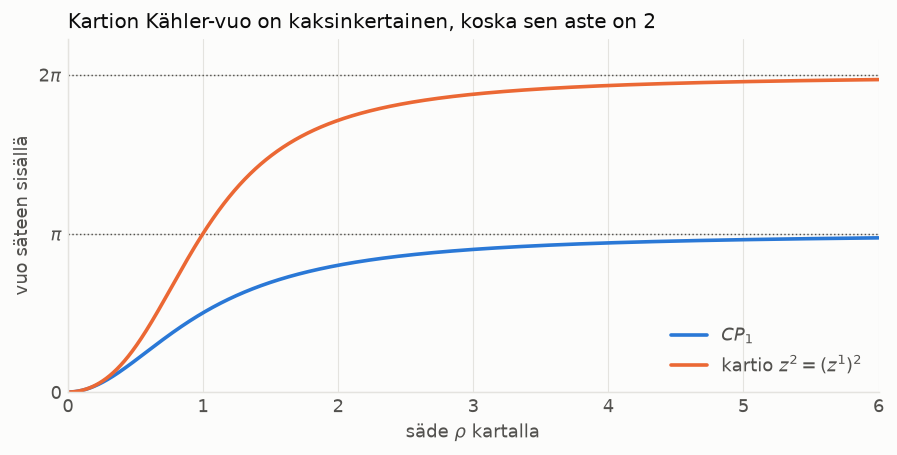

In [4]:
om = "form_from_matrix(cp2_kahler_matrix())"
d1 = lab.numeric("", f"top_coef(form_pullback({om},cp2_X,[aa,bb,0,0],[aa,bb]))", ["aa", "bb"])
d2 = lab.numeric("", f"top_coef(form_pullback({om},cp2_X,[aa,bb,aa^2-bb^2,2*aa*bb],[aa,bb]))", ["aa", "bb"])

def cumulative_flux(density):
    t = np.linspace(0, np.pi/2 - 1e-5, 200001)
    rho = np.tan(t)
    f = 2*np.pi*rho*np.asarray(density(rho, 0*rho), float)/np.cos(t)**2
    return rho, np.concatenate([[0], np.cumsum((f[1:] + f[:-1])/2*np.diff(t))])

rho, phi1 = cumulative_flux(d1)
rho, phi2 = cumulative_flux(d2)
assert abs(phi1[-1] - np.pi) < 1e-3 and abs(phi2[-1] - 2*np.pi) < 1e-3
assert np.max(np.abs(phi1 - np.pi*rho**2/(1 + rho**2))) < 1e-3
print("vuo CP1:", round(phi1[-1]/np.pi, 5), "pi, vuo kartio:", round(phi2[-1]/np.pi, 5), "pi")

m = rho <= 6
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.axhline(np.pi, color=MUTED, lw=0.8, ls=":"); ax.axhline(2*np.pi, color=MUTED, lw=0.8, ls=":")
ax.plot(rho[m], phi1[m], color=BLUE, label="$CP_1$")
ax.plot(rho[m], phi2[m], color=ORANGE, label="kartio $z^2=(z^1)^2$")
ax.set_yticks([0, np.pi, 2*np.pi]); ax.set_yticklabels(["0", r"$\pi$", r"$2\pi$"])
ax.set_xlim(0, 6); ax.set_ylim(0, 7)
ax.set_xlabel(r"säde $\rho$ kartalla"); ax.set_ylabel("vuo säteen sisällä")
ax.set_title("Kartion Kähler-vuo on kaksinkertainen, koska sen aste on 2")
ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

## Geodeesi, jonka suunta kääntyy

Ratkaisu $z^1=\tan(x)\,e^{ia(u)}$, $z^2=0$ toteuttaa sekä Kähler- että tilavuustermin (`tests/test-field-equations.mac`).
Kuvissa $a(u)=\sin u$. Indusoitu kenttä on $J_{ux}=-\tfrac12\sin(2x)\,a'(u)$.

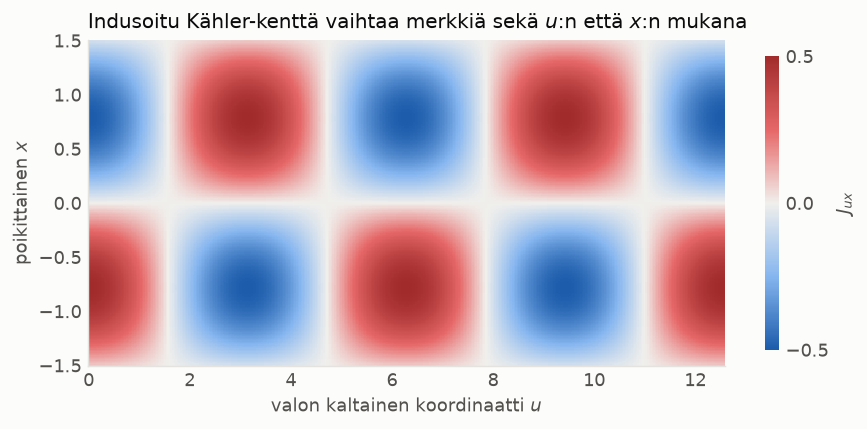

In [5]:
setup = ("JH:H_kahler()$ xl:[uu,vv,xx,yy]$ s:[tan(xx)*cos(sin(uu)),tan(xx)*sin(sin(uu)),0,0]$ "
         "e:append([(uu+vv)/2,xx,yy,(vv-uu)/2],s)$ Ji:induced_kahler_form(JH,H_X,e,xl)$")
Jux = lab.numeric(setup, "Ji[1,3]", ["uu", "xx"])
u, x = np.meshgrid(np.linspace(0, 4*np.pi, 401), np.linspace(-1.5, 1.5, 241))
vals = np.asarray(Jux(u, x), float)
assert np.max(np.abs(vals + 0.5*np.sin(2*x)*np.cos(u))) < 1e-8

cmap = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#e66767", "#a12b2b"])
fig, ax = plt.subplots(figsize=(7, 3.4))
im = ax.pcolormesh(u, x, vals, cmap=cmap, vmin=-0.5, vmax=0.5, shading="auto", rasterized=True)
ax.grid(False)
ax.set_xlabel("valon kaltainen koordinaatti $u$"); ax.set_ylabel("poikittainen $x$")
ax.set_title("Indusoitu Kähler-kenttä vaihtaa merkkiä sekä $u$:n että $x$:n mukana")
fig.colorbar(im, ax=ax, label="$J_{ux}$", shrink=0.9, ticks=[-0.5, 0, 0.5]).outline.set_visible(False)
fig.tight_layout(); plt.show()

## $CP_2$-projektio

Kuvassa on pinnan projektio $z^1$-tasoon. Jokaisella $u$:n arvolla piste kulkee geodeesia pitkin origon kautta, ja suunta kääntyy $u$:n mukana.

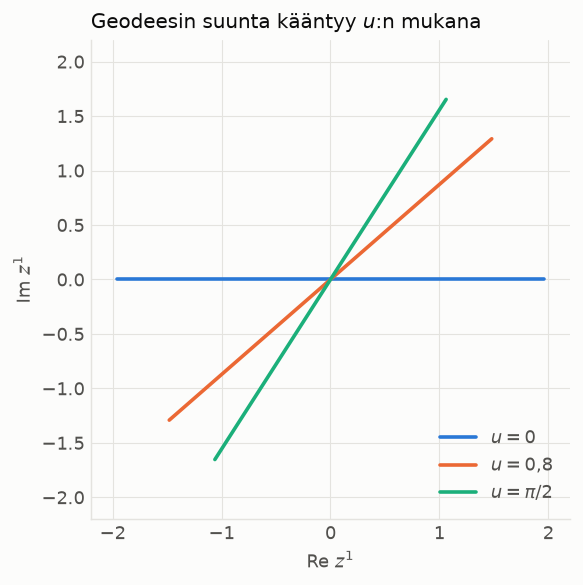

In [6]:
xs = np.linspace(-1.1, 1.1, 201)
fig, ax = plt.subplots(figsize=(4.6, 4.6))
for ui, col, name in [(0.0, BLUE, "$u=0$"), (0.8, ORANGE, "$u=0{,}8$"), (np.pi/2, AQUA, r"$u=\pi/2$")]:
    a = np.sin(ui)
    ax.plot(np.tan(xs)*np.cos(a), np.tan(xs)*np.sin(a), color=col, label=name)
ax.set_aspect("equal"); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
ax.set_xlabel("Re $z^1$"); ax.set_ylabel("Im $z^1$")
ax.set_title("Geodeesin suunta kääntyy $u$:n mukana")
ax.legend(loc="lower right")
fig.tight_layout(); plt.show()